# Segmentación de clientes de una marca de moda mexicana
Caso práctico para la vacante AI & MarTech Developer Intern de Keyrus.

La marca vende en su tienda online y en 5 tiendas físicas, tiene unos 3.000 clientes y casi 3 años de historial, pero hoy le habla a todos igual. Antes de diferenciar su comunicación, el equipo de CRM quiere responder tres preguntas:

1. ¿Quiénes se interesan por las nuevas colecciones?
2. ¿Quiénes compran de forma recurrente?
3. ¿Quiénes son los clientes de mayor valor?

Este notebook cuenta el análisis paso a paso. La lógica está en módulos de Python con pruebas (`src/customer_segmentation/`) que el notebook importa, así que es el mismo código que podría correr a diario en producción.

| Sección | Qué responde del enunciado |
|---|---|
| 1. Calidad de datos | Qué problemas encontré, cómo los traté y qué habría pasado sin corregirlos |
| 2. Tabla de clientes | La base de comportamiento por cliente |
| 3. Las tres preguntas | Criterio, número de clientes y % de ventas |
| 4. Arquetipos | Cuántos grupos, por qué, qué los caracteriza y cómo explicarlos a CRM |
| 5. Conclusiones | Qué haría la marca mañana y cómo se lleva a producción |

El trabajo sigue los tres pilares del Human Orchestrated Model de Keyrus. Intelligence Foundations corresponde a tener datos confiables y privados (secciones 1 y 2). Human in Command, a usar criterios explícitos que el negocio puede revisar y ajustar (secciones 3 y 4). Performance Steering, a medir y llevar el resultado a producción (sección 5).

### Privacidad
Los datos incluyen información personal (email, teléfono y fecha de nacimiento), así que los traté como reales:
- Solo `privacy.py` lee `customers.csv`. El email y el teléfono se reemplazan por tokens HMAC-SHA256 con una clave secreta, la fecha de nacimiento por un rango de edad, y la columna de notas en texto libre se elimina.
- El notebook solo muestra datos agregados. Ninguna celda imprime datos de una persona.
- Los datos y la clave están fuera del control de versiones (`.gitignore`). Usé IA como asistente de código y solo le compartí esquemas y agregados.

### Cómo reproducirlo
Los pasos están en el `README.md`: copiar los datos, crear la clave, seudonimizar una vez y ejecutar todas las celdas.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from customer_segmentation import charts, cleaning, config, segmentation

charts.apply_style()
pd.set_option("display.max_colwidth", 90)
print(f"Fecha de corte del análisis: {config.REFERENCE_DATE:%d/%m/%Y}")

Fecha de corte del análisis: 30/09/2026


## 1. Calidad de datos (Intelligence Foundations)

> "Revisa la calidad antes de analizar. Documenta qué problemas encontraste, cómo los trataste y qué habría pasado con tus conclusiones si no los corriges."

`cleaning.run` aplica 15 reglas. Cada una registra cuántas filas toca y ninguna borra datos sin dejar constancia: cada fila se corrige, se marca o se excluye con un motivo. Las reglas están en código con pruebas, no en celdas, para que se puedan reproducir y llevar a producción.

In [2]:
orders_raw = cleaning.read_raw("orders")
items_raw = cleaning.read_raw("order_items")
products_raw = cleaning.read_raw("products")
customers_pseudo = pd.read_parquet(config.PROCESSED_DIR / "customers_pseudo.parquet")

result = cleaning.run(customers_pseudo, orders_raw, items_raw, products_raw)
charts.table(result["issue_log"])

,Código,Tabla,Problema,Filas afectadas,Tratamiento
0,P1,productos,"Etiqueta de colección escrita de formas no estándar (OI-26, oi26, 'OI 26')",8,"Normalizada a la etiqueta canónica (mayúsculas, sin espacios ni guiones)"
1,P2,productos,Los básicos no tienen fecha de lanzamiento,24,No es un error: son atemporales. Se marcan como no de temporada
2,C1,clientes,Misma persona registrada con dos IDs de cliente (mismo token de email),116,Fusionada en el ID original; sus órdenes se reasignan a ese ID
3,C1b,clientes,Los registros duplicados no coinciden en el consentimiento de WhatsApp,55,Gana el más restrictivo: hay consentimiento solo si todos los registros lo dieron
4,C4,clientes,"Cuentas del dominio de email de la marca (personal, tiendas o pruebas)",16,Fuera del análisis por cliente; sus ventas siguen en el total de la marca
5,O1,órdenes,Orden sin customer_id (compra de invitado en tienda),800,Se mantiene en la venta de la marca; fuera del análisis por cliente
6,O2,órdenes,customer_id que no existe en la tabla de clientes,40,Se mantiene en la venta de la marca; fuera del análisis por cliente
7,C1c,órdenes,Órdenes hechas con un ID de cliente duplicado,302,Reasignadas al ID original del cliente
8,O3,órdenes,Orden anterior al registro del cliente,381,No es un error: compra en tienda y registro posterior. La historia del cliente se mide...
9,O4,órdenes,Órdenes devueltas o canceladas,1.354,Fuera de la venta neta


Cómo leer el registro de problemas:
- C1: 116 personas estaban registradas dos veces (mismo email, mismo día de registro y canal opuesto) y se fusionaron. Por eso quedan 3.006 clientes únicos, en línea con los cerca de 3.000 del enunciado. Cuando los dos registros no coincidían en el consentimiento, se quedó el más restrictivo (C1b).
- C4 e I3: 16 cuentas del dominio interno `@marcamoda.mx` (con un descuento promedio de 23 %, frente al 8,6 % general) y un comprador de 50 a 120 unidades por línea quedan fuera del análisis por cliente, aunque sus ventas siguen contando en el total de la marca. Son inferencias, no hechos: se detectan con reglas y las presento como hipótesis para validar con el negocio.
- I1 e I2: 627 líneas idénticas en todas sus columnas se tratan como doble carga y se eliminan. En cambio, 1.088 líneas repiten producto dentro de la misma orden con distinto descuento y se conservan como unidades reales. Las dos decisiones también son inferencias para validar.
- P1 y P3: la etiqueta OI26 aparecía con 5 variantes mal escritas (OI-26, oi26, "OI 26", entre otras), y 2.006 líneas se vendieron antes del lanzamiento de su producto. Esas líneas cuentan como venta, pero no como compra de colección nueva.
- O3: 381 órdenes son anteriores al registro del cliente. No es un error: la gente compra en tienda y se registra después. Por eso la historia de cada cliente (por ejemplo, a qué lanzamientos pudo responder) se mide desde su primera compra y no desde su registro.

### ¿Qué habría pasado sin limpiar?
Las mismas métricas, calculadas sobre los datos tal como vienen y sobre los datos limpios:

In [3]:
comparison = cleaning.compare(orders_raw, items_raw, products_raw, result)
charts.table(comparison)

,Métrica,Sin limpiar,Limpio,Reglas que lo explican
0,Clientes con compras,3.031,2.877,"C1, C4, I3, O2"
1,Mejor cliente,comprador por volumen,cliente minorista,I3
2,Venta del mejor cliente (MXN),2.484.817,"155.496,50",I3
3,Mejor cliente frente al segundo (veces),"2,94","1,02",I3
4,Cuentas no minoristas en el top 10,2,0,"C4, I3"
5,% de la venta del 10 % de clientes que más compra,"55,86","52,50","I3, C4, O4"
6,Clientes con 2 o más órdenes,2.358,2.244,"C1, O4"
7,Más órdenes de un solo cliente,420,36,C4
8,Cliente con más órdenes,cuenta interna,cliente minorista,C4
9,SKU de OI26 en el catálogo,28,36,P1


Las conclusiones que cambian:
- El mejor cliente habría sido un comprador por volumen, que compra 2,9 veces lo que el segundo.
- El cliente más fiel habría sido una cuenta operativa de tienda, con 420 órdenes.
- La campaña de OI26 habría llegado a un 26 % más de personas. Los dos errores se compensan solo en parte: al normalizar las etiquetas aparecen 60 compradores más, pero 143 personas solo habían comprado productos de OI26 antes de su lanzamiento.

La venta cargada supera a la venta neta real en 17,8 %
  errores de datos (duplicados, devueltas y canceladas): 8,4 puntos
  descuentos (definición de venta neta, no un error): 9,4 puntos


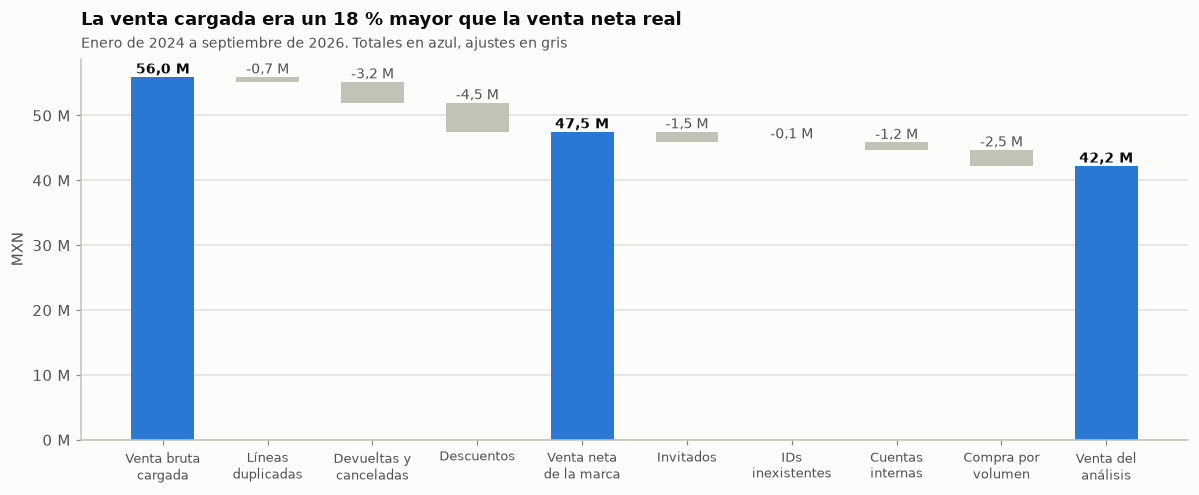

In [4]:
bridge = cleaning.sales_bridge(items_raw, result)
share = bridge.set_index("step")["share_of_brand_net"]
inflation = charts.number((share.iloc[0] - 1) * 100, 1)
errors = charts.number(-share[["Duplicated lines", "Returned and cancelled orders"]].sum() * 100, 1)
discounts = charts.number(-share["Discounts"] * 100, 1)
print(f"La venta cargada supera a la venta neta real en {inflation} %")
print(f"  errores de datos (duplicados, devueltas y canceladas): {errors} puntos")
print(f"  descuentos (definición de venta neta, no un error): {discounts} puntos")
charts.sales_bridge_chart(bridge)
plt.show()

## 2. Tabla de clientes

Una fila por cliente del análisis y 24 variables, documentadas en un diccionario de datos que está junto al código. La suma de ventas por cliente cuadra con el puente de ventas: el código lo verifica y se detiene si no cuadra.

Para medir el interés por lo nuevo usé el momento de la compra. Una colección concentra un tercio de su venta en el primer mes, así que comprar en ese pico, en vez de esperar, es la señal. De ahí sale la ventana de lanzamiento de 30 días:

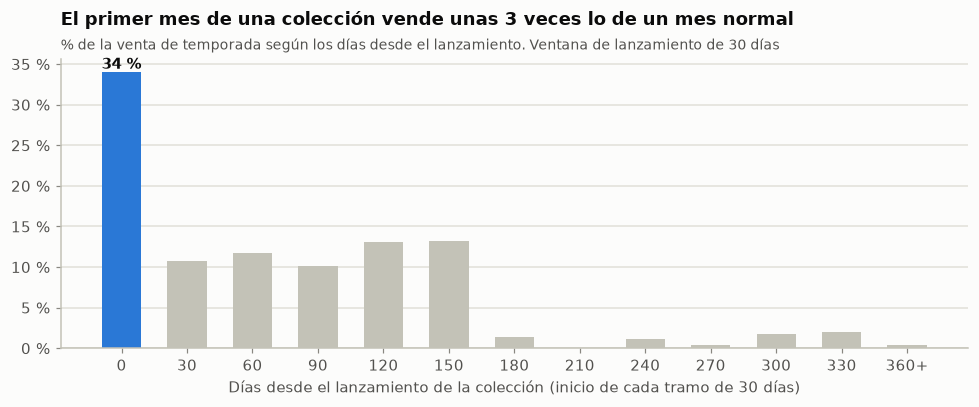

In [5]:
customer_features = segmentation.build_features(result)
charts.launch_curve_chart(segmentation.launch_curve(result))
plt.show()

In [6]:
buyers = customer_features[customer_features["has_purchase"]]
n_customers, n_buyers = charts.number(len(customer_features)), charts.number(len(buyers))
print(f"{n_customers} clientes en el análisis, {n_buyers} con compras")
charts.table(segmentation.feature_dictionary())

2.989 clientes en el análisis, 2.877 con compras


,Variable,Descripción
0,customer_id,ID maestro del cliente (duplicados ya fusionados)
1,ciudad,Ciudad declarada en el registro
2,canal_registro,"Canal de registro: online, tienda o both (duplicados fusionados)"
3,age_band,Rango de edad a la fecha de corte (vacío si la fecha falta o no es válida)
4,fecha_registro,Fecha de registro más antigua
5,contactable_email,Aceptó email y tiene un email válido
6,contactable_whatsapp,Aceptó WhatsApp y tiene un teléfono válido
7,contactable_any,Se le puede contactar por al menos un canal
8,has_purchase,Tiene al menos una orden completada
9,n_orders,Órdenes completadas (frecuencia)


## 3. Las tres preguntas (Human in Command)

> "Para cada una, primero define el criterio (...) y luego cuantifica: cuántos clientes son y cuánto representan en ventas."

Cada criterio es una regla que se puede explicar en una frase a alguien de CRM, y sus umbrales están en `config.py`. Cada umbral se apoya en la forma de la distribución y lo comprobé con una tabla de sensibilidad.

In [7]:
flags = segmentation.segment_flags(customer_features)
since_12m = pd.Timestamp(config.REFERENCE_DATE) - pd.DateOffset(months=config.RECENT_MONTHS)
brand_total = segmentation.brand_net_sales(result)
brand_total_12m = segmentation.brand_net_sales(result, since=since_12m)

answers = segmentation.answer_table(customer_features, flags, brand_total, brand_total_12m)
charts.table(answers)

,Pregunta,Criterio,Clientes,% de los compradores,% de la venta (3 años),% de la venta (12 meses),% contactable,% que solo compra básicos
0,P1. ¿Quiénes se interesan por las nuevas colecciones?,Compró en los primeros 30 días del lanzamiento en al menos el 50 % de los lanzamientos...,539,"18,7 %","52,7 %","55,2 %","82,6 %","0,0 %"
1,P2. ¿Quiénes compran de forma recurrente?,"3 o más días de compra, mediana de 60 días o menos entre compras y última compra hace ...",844,"29,3 %","67,6 %","72,8 %","81,6 %","59,5 %"
2,P3. ¿Quiénes son los clientes de mayor valor?,25.000 MXN o más de venta neta en los últimos 12 meses,188,"6,5 %","39,5 %","42,0 %","87,2 %","0,0 %"


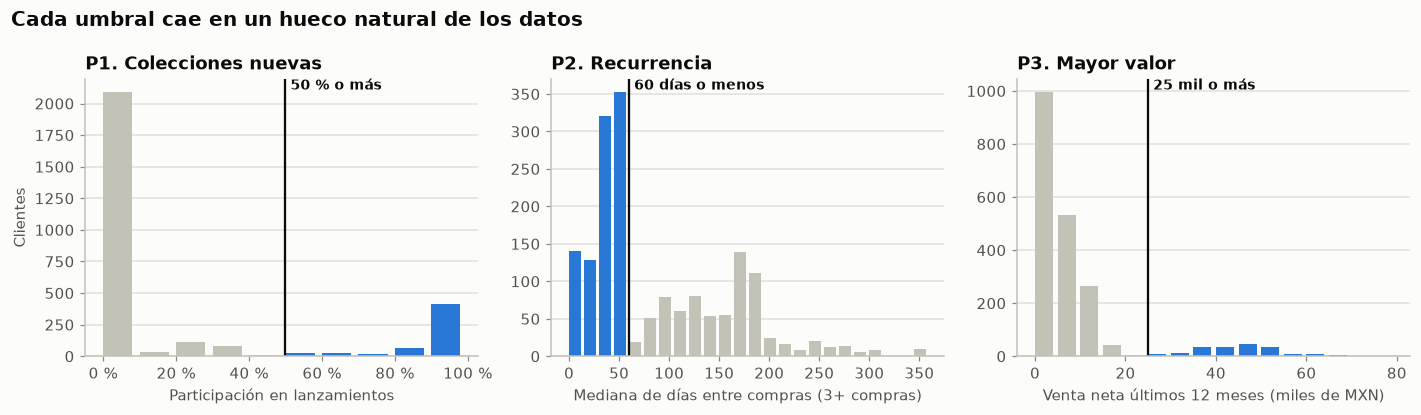

In [8]:
charts.threshold_charts(customer_features)
plt.show()

| Pregunta | Criterio | Por qué este umbral |
|---|---|---|
| P1. Colecciones nuevas | Compró en los primeros 30 días del lanzamiento en al menos el 50 % de los lanzamientos que tuvo disponibles | La participación se divide en dos: casi todos están en 0 % o en 100 %. La tasa se ajusta por oportunidad, para que un cliente nuevo no compita contra uno de 2024 |
| P2. Recurrentes | 3 o más días de compra, mediana de 60 días o menos entre compras y última compra hace 90 días o menos | Hay dos ritmos (de 30 a 60 días y de 90 a 270) con pocos clientes en medio. La recencia separa a los recurrentes que siguen comprando de los que ya se fueron |
| P3. Mayor valor | 25.000 MXN o más de venta neta en los últimos 12 meses | Entre 20 y 30 mil solo hay 12 clientes, así que el corte cae en un hueco. Uso 12 meses para medir el valor actual y no castigar a los clientes nuevos |

En resumen, 1 de cada 5 compradores responde a los lanzamientos y genera más de la mitad de la venta de los tres años. El 60 % de los recurrentes compra solo básicos, lo que muestra que la recurrencia viene de dos tipos de cliente distintos. Los 188 clientes de mayor valor (6,5 % de los compradores) generan el 39,5 % de la venta de los tres años y el 42 % de la del último año.

### ¿Cómo se cruzan los tres grupos?

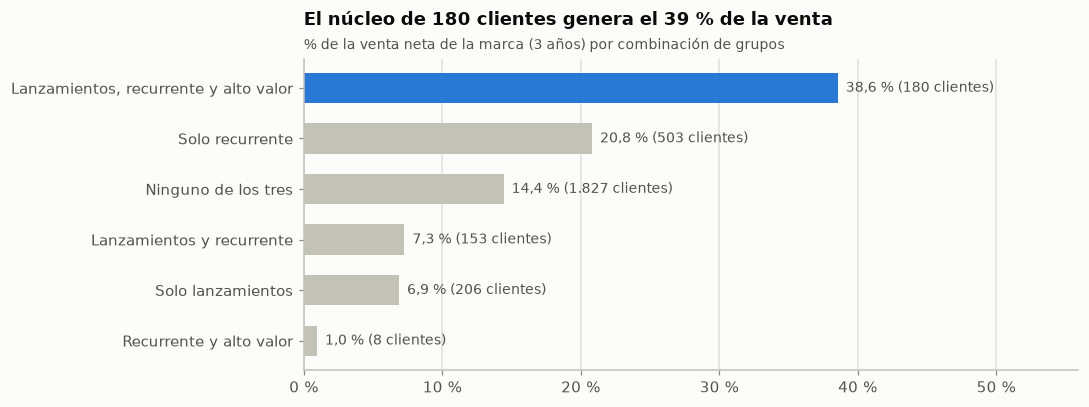

In [9]:
overlaps = segmentation.overlap_table(customer_features, flags, brand_total)
charts.overlap_chart(overlaps)
plt.show()

De los 188 clientes de mayor valor, 180 (96 %) también compran en los lanzamientos y son recurrentes. Para la marca, eso quiere decir que sus mejores clientes dependen de los lanzamientos. En el otro extremo, el 64 % de los compradores no cumple ningún criterio y aporta el 14 % de la venta.

### ¿Cambia la respuesta si muevo el umbral?

In [10]:
charts.table(segmentation.sensitivity_table(customer_features, brand_total_12m))

,Pregunta,Escenario,Clientes,% de la venta (12 meses)
0,P1. ¿Quiénes se interesan por las nuevas colecciones?,participación de al menos el 34 %,552,"55,5 %"
1,P1. ¿Quiénes se interesan por las nuevas colecciones?,participación de al menos el 50 %,539,"55,2 %"
2,P1. ¿Quiénes se interesan por las nuevas colecciones?,participación de al menos el 67 %,495,"48,6 %"
3,P1. ¿Quiénes se interesan por las nuevas colecciones?,participación de al menos el 100 %,411,"36,8 %"
4,P2. ¿Quiénes compran de forma recurrente?,"brecha hasta 45 días, última compra hace 90 días o menos",552,"59,8 %"
5,P2. ¿Quiénes compran de forma recurrente?,"brecha hasta 60 días, última compra hace 90 días o menos",844,"72,8 %"
6,P2. ¿Quiénes compran de forma recurrente?,"brecha hasta 90 días, última compra hace 90 días o menos",877,"74,0 %"
7,P2. ¿Quiénes compran de forma recurrente?,"brecha hasta 60 días, última compra hace 60 días o menos",813,"70,9 %"
8,P2. ¿Quiénes compran de forma recurrente?,"brecha hasta 60 días, última compra hace 180 días o menos",856,"73,2 %"
9,P3. ¿Quiénes son los clientes de mayor valor?,venta en 12 meses de 15.000 MXN o más,233,"45,9 %"


En P1 y P3, mover el umbral dentro de un rango razonable cambia el grupo menos de un 10 %: P1 va de 552 a 495 clientes entre el 34 % y el 67 %, y P3 de 192 a 180 clientes entre 20 y 30 mil MXN. En P2 el corte va en 60 días porque 45 cae justo sobre el ritmo de los compradores de básicos: con 45 días el grupo bajaría de 844 a 552 clientes.

## 4. Arquetipos

> "Agrupa a los clientes según su comportamiento de compra. (...) Justifica cuántos grupos elegiste, qué caracteriza a cada uno y cómo se lo explicarías a alguien funcional."

Los grupos de las tres preguntas se superponen. Los arquetipos, en cambio, asignan un solo grupo a cada cliente. Usé K-Means sobre 7 variables de comportamiento (recencia, frecuencia, ticket, participación en lanzamientos, temporada frente a básicos, descuento y canal), con logaritmo donde hacía falta y estandarizadas. Los clientes sin compras forman su propio grupo.

### ¿Cuántos grupos?

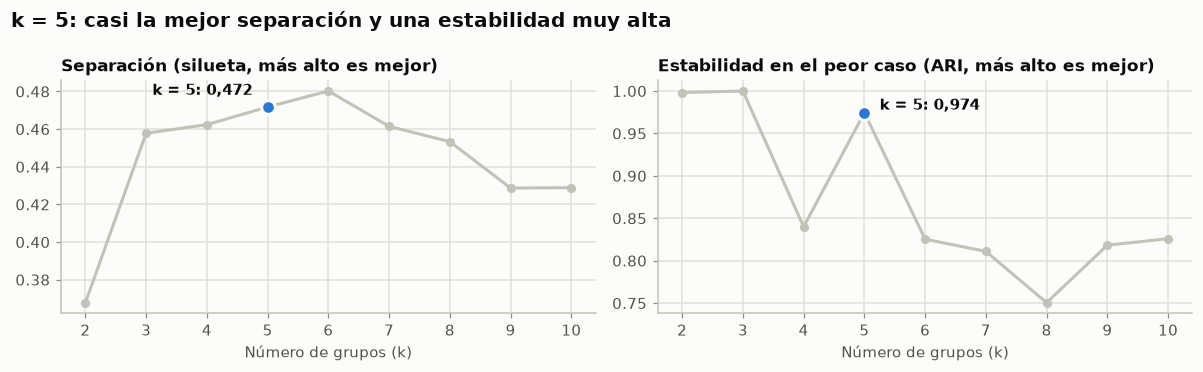

,k,Separación (silueta),Estabilidad en el peor caso (ARI),Grupo más pequeño
0,2,"0,368","0,998",1.060
1,3,"0,458",1,527
2,4,"0,462","0,840",526
3,5,"0,472","0,974",525
4,6,"0,480","0,825",350
5,7,"0,461","0,811",187
6,8,"0,453","0,751",187
7,9,"0,429","0,818",187
8,10,"0,429","0,826",146


In [11]:
matrix = segmentation.standardize(segmentation.clustering_matrix(buyers))
k_table = segmentation.evaluate_k(matrix)
charts.k_selection_chart(k_table, segmentation.N_ARCHETYPES)
plt.show()
charts.table(k_table)

Elegí k = 5 por tres razones:
1. Su separación (silueta) está prácticamente empatada con la mejor: 0,472 frente a 0,480 con k = 6.
2. Es muy estable. Al volver a entrenar con submuestras del 80 %, los grupos coinciden en un 97 % incluso en el peor caso, frente al 83 % con k = 6. Con 2 o 3 grupos la estabilidad es aún mayor, pero son demasiado pocos: con k = 3 los cazadores de rebajas quedan mezclados con los dos grupos dormidos, y CRM les hablaría de forma distinta.
3. Con k = 6 los tres grupos principales salen idénticos. El grupo extra solo reparte de otra forma a los clientes dormidos de bajo valor, que juntos aportan el 6 % de la venta, y eso no cambia lo que haría CRM.

Además, el clustering llega a los mismos grupos de las preguntas 1 y 2, que se obtuvieron por otro camino.

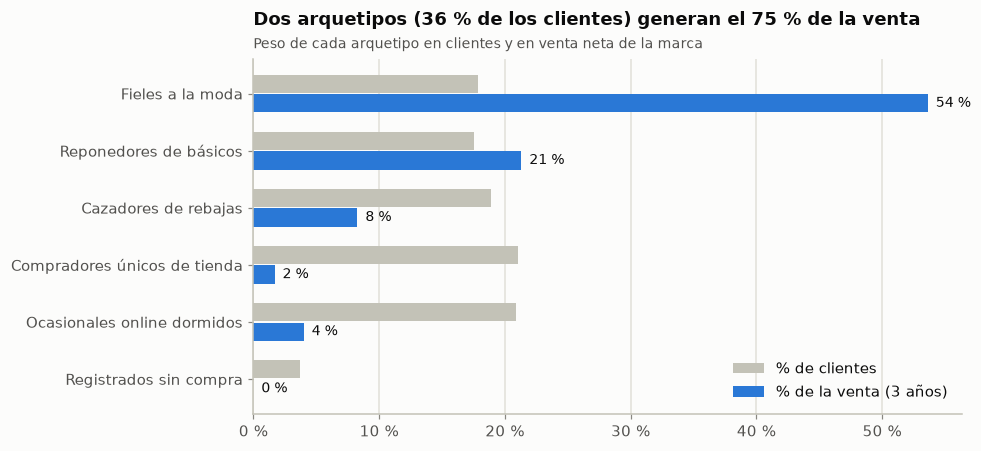

In [12]:
customer_archetype = segmentation.assign_archetypes(customer_features)
profile = segmentation.profile_archetypes(customer_features, flags, customer_archetype, brand_total)
charts.archetype_share_chart(profile)
plt.show()

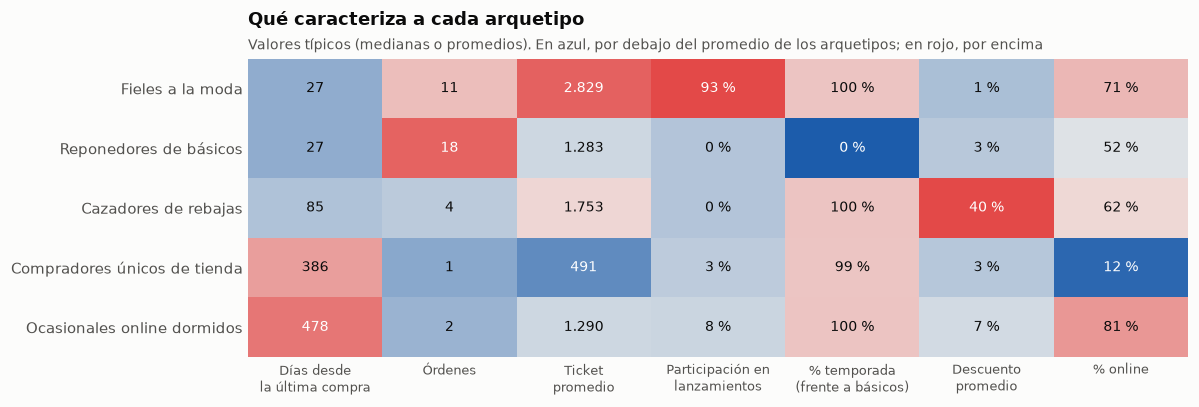

In [13]:
charts.archetype_heatmap(profile)
plt.show()

In [14]:
charts.table(profile.set_index("name"))

,Clientes,% de los clientes,Venta neta 3 años (MXN),% de la venta (3 años),Días desde la última compra (mediana),Órdenes (mediana),Días entre compras (mediana),"Ticket promedio (mediana, MXN)",Participación en lanzamientos,% de venta de temporada,Descuento promedio (%),% de órdenes online,% en P1,% en P2,% en P3,% contactable
Arquetipo,,,,,,,,,,,,,,,,
Fieles a la moda,535,"17,9 %","25.487.090,90","53,6 %",27,11,"30,50","2.829,12","93,4 %","99,9 %","1,38","71,3 %","98,3 %","63,9 %","35,1 %","82,6 %"
Reponedores de básicos,525,"17,6 %","10.126.456,80","21,3 %",27,18,46,"1.282,74","0,0 %","0,0 %","3,37","51,9 %","0,0 %","95,6 %","0,0 %","81,1 %"
Cazadores de rebajas,565,"18,9 %","3.930.842,40","8,3 %",85,4,175,1.753,"0,0 %","99,9 %","40,04","62,2 %","0,0 %","0,0 %","0,0 %","86,0 %"
Compradores únicos de tienda,628,"21,0 %",801.281,"1,7 %","385,50",1,"140,50","491,05","3,3 %","99,5 %","3,03","12,1 %","0,8 %","0,0 %","0,0 %","84,4 %"
Ocasionales online dormidos,624,"20,9 %","1.902.133,30","4,0 %",478,2,120,"1.289,55","7,9 %","100,0 %","6,96","80,7 %","1,3 %","0,0 %","0,0 %","83,3 %"
Registrados sin compra,112,"3,7 %",0,"0,0 %",,0,,,,,,,"0,0 %","0,0 %","0,0 %","85,7 %"


### Una prueba externa: ¿cuándo compran los cazadores de rebajas?
El mes de compra no se usó para formar los grupos, así que sirve para comprobar que el arquetipo es real:

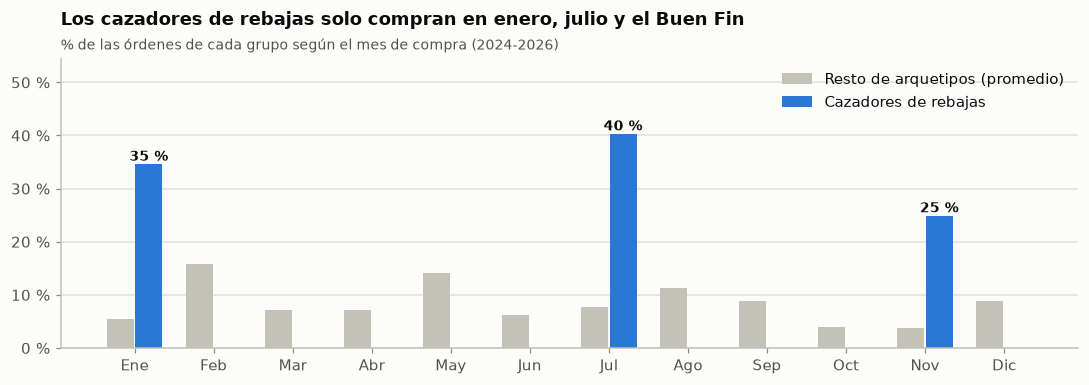

In [15]:
charts.purchase_month_chart(segmentation.purchase_months(result, customer_archetype))
plt.show()

Compran solo en enero, julio y noviembre, que coinciden con las rebajas de invierno, las de verano y el Buen Fin. Esto confirma que el arquetipo existe y le dice a CRM cuándo escribirles.

### Cómo se lo explicaría a alguien de CRM

| Arquetipo | Clientes (% de la venta) | Es el cliente que | Qué haría CRM |
|---|---|---|---|
| Fieles a la moda | 535 (54 %) | compra cada mes, llega primero a cada lanzamiento y casi siempre paga precio completo | Acceso anticipado y preventa, sin descuentos: compra igual y se perdería margen |
| Reponedores de básicos | 525 (21 %) | vuelve más o menos cada seis semanas por sus básicos de siempre | Recordatorio automático de reposición a los 45 días |
| Cazadores de rebajas | 565 (8 %) | solo aparece en enero, julio y el Buen Fin, con 40 % de descuento | Comunicación concentrada en esas tres temporadas |
| Compradores únicos de tienda | 628 (2 %) | hizo una compra pequeña en tienda hace un año | Incentivo de segunda compra y registro de su consentimiento en tienda |
| Ocasionales online dormidos | 624 (4 %) | compró un par de veces online y no volvió | Campaña automática de recuperación con pocos intentos |
| Registrados sin compra | 112 (0 %) | se registró y nunca compró | Bienvenida con incentivo para la primera compra |

### De modelo a reglas
Emarsys segmenta con condiciones sobre atributos del cliente. Un árbol de decisión de 3 niveles traduce los arquetipos a reglas que CRM puede leer y configurar:

In [16]:
accuracy, rules = segmentation.surrogate_rules(customer_features, customer_archetype)
print(f"Precisión con validación cruzada de 5 particiones: {charts.number(accuracy * 100, 1)} %\n")
print(rules)

Precisión con validación cruzada de 5 particiones: 94,1 %

|--- descuento promedio (%) <= 25,0
|   |--- días desde la última compra <= 138,5
|   |   |--- proporción de venta de temporada <= 0,5
|   |   |   |--- arquetipo: Reponedores de básicos
|   |   |--- proporción de venta de temporada >  0,5
|   |   |   |--- arquetipo: Fieles a la moda
|   |--- días desde la última compra >  138,5
|   |   |--- proporción de órdenes online <= 0,3
|   |   |   |--- arquetipo: Compradores únicos de tienda
|   |   |--- proporción de órdenes online >  0,3
|   |   |   |--- arquetipo: Ocasionales online dormidos
|--- descuento promedio (%) >  25,0
|   |--- ticket promedio (MXN) <= 407,4
|   |   |--- arquetipo: Compradores únicos de tienda
|   |--- ticket promedio (MXN) >  407,4
|   |   |--- ticket promedio (MXN) <= 533,6
|   |   |   |--- arquetipo: Cazadores de rebajas
|   |   |--- ticket promedio (MXN) >  533,6
|   |   |   |--- arquetipo: Cazadores de rebajas



El árbol acierta en 94 de cada 100 clientes con validación cruzada. Las dos últimas ramas de ticket dan el mismo arquetipo y se leen como una sola regla: descuento promedio mayor al 25 % y ticket mayor a 407 MXN corresponde a un cazador de rebajas.

## 5. Conclusiones (Performance Steering)

### Qué encontré
1. Sin limpiar, el mejor cliente era un comprador por volumen y el más fiel era una cuenta de tienda. Sumar líneas duplicadas y órdenes devueltas o canceladas inflaba la venta en un 8,4 %; al aplicar además los descuentos, la venta cargada era un 18 % mayor que la real. La limpieza cambia las conclusiones, no solo las cifras.
2. Los fieles a la moda (54 %) y los reponedores de básicos (21 %) son el 36 % de los clientes y generan el 75 % de la venta. Compran cosas distintas y a ritmos distintos, así que no se les puede hablar igual.
3. El 96 % de los clientes de mayor valor también compra en los lanzamientos y es recurrente.
4. Los fieles a la moda compran casi siempre a precio completo (1,4 % de descuento promedio). Una promoción enviada a todos les da un descuento en algo que iban a comprar de todas formas.
5. Los cazadores de rebajas solo compran en enero, julio y el Buen Fin, así que el calendario importa para hablarles.

### Cómo llevarlo al día a día (tema de la Fase 2)
- SAP Customer Data Cloud es la fuente de identidad y consentimiento. Su ID de cliente y su email resolverían los duplicados en el origen, y sus consentimientos definen a quién se puede contactar.
- Este pipeline, programado a diario, recalcula variables, banderas y arquetipos. Las reglas del árbol se pueden configurar directamente como segmentos.
- SAP Emarsys recibe los atributos (arquetipo, P1, P2, P3 y contactabilidad) y ejecuta las automatizaciones: preventa para los fieles, reposición a los 45 días, campañas de temporada para los cazadores y recuperación para los dormidos.
- Medición: indicadores por arquetipo (venta, recencia, respuesta a campañas) y cuántos clientes pasan de un arquetipo a otro cada mes. Por ejemplo, cuántos compradores únicos de tienda hacen una segunda compra.
- Siguiente paso con IA: un flujo con LLM que redacte el texto de cada campaña según el arquetipo, a partir de su perfil agregado (nunca datos personales) y con aprobación humana antes de enviar.

### Supuestos a validar con el negocio (Human in Command)
Que las cuentas `@marcamoda.mx` son internas, que el comprador por volumen no es un cliente minorista, que las líneas idénticas son una doble carga y que el mismo producto dos veces en una orden con distinto descuento son dos unidades reales. Los umbrales de los criterios están en `config.py` y se pueden ajustar en una línea.